# RQ3 完整分析：Conformal Prediction 与海洋区域可靠性

**研究问题：**固定的 72 小时漂流轨迹预测模型，能否给出可靠的不确定性范围？
这种可靠性是否会随 Shelf、Kuroshio Core、Transition 和 Other Offshore 等海洋环境而变化？

这份 Notebook 是 `RQ3/` 文件夹的中文阅读入口。它不会另写一套不同的算法，而是：

1. 检查 RQ3 所需输入；
2. 调用现有 `run_all.py` 完整运行 `01–04` 四个分析脚本；
3. 读取所有正式 CSV/PNG 输出；
4. 解释 global、Mondrian、drifter-max、cluster bootstrap 和 integrity audit；
5. 总结可以写进最终报告的结果、限制与结论。

> RQ3 不会提高 FNN 中心预测的准确度。它回答的是：真实位置落在预测区域内的频率是否达到目标，
> 以及为了达到该 coverage，预测区域需要有多大。

In [1]:
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "RQ3").exists() and (p / "data" / "processed").exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("找不到项目根目录。请从 data3001-project 或其子目录运行本 Notebook。")

RQ3 = PROJECT_ROOT / "RQ3"
OUTPUT = RQ3 / "output"
OUTPUT.mkdir(exist_ok=True)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "PingFang SC"]
plt.rcParams["axes.unicode_minus"] = False

print("项目目录：", PROJECT_ROOT)
print("RQ3 目录：", RQ3)
print("结果目录：", OUTPUT)

项目目录： /Users/roger/Documents/data3001-project
RQ3 目录： /Users/roger/Documents/data3001-project/RQ3
结果目录： /Users/roger/Documents/data3001-project/RQ3/output


## 1. RQ3 文件结构与每个文件的职责

| 文件 | 作用 | 主要输出 |
|---|---|---|
| `01_global_conformal.py` | 重建固定 FNN 预测；计算 global 80/90/95% pointwise conformal regions；整轨迹 band | lead-time coverage、半径、regime 诊断、示例轨迹 |
| `02_regime_and_drifter_aware.py` | 比较 Global、Mondrian 和 drifter-max 三种 72 h 方法 | 各 regime coverage、半径和面积 |
| `03_paired_cluster_bootstrap.py` | 以完整 test drifter 为单位做 2,000 次配对 bootstrap | 方法差异的 95% 区间 |
| `04_integrity_and_drifter_audit.py` | 独立核对 case ID、分区、半径、coverage 和 RQ1 误差 | 42 项数据与数值完整性检查 |
| `run_all.py` | 一键运行完整 RQ3 pipeline | 生成/更新 `RQ3/output/` |

注意：`run_all.py` 会为了让各脚本可以独立复现而重复运行部分前序计算，因此需要几分钟是正常的。

In [2]:
inventory = []
for path in sorted(RQ3.iterdir()):
    if path.name.startswith("."):
        continue
    if path.is_file():
        inventory.append({"name": path.name, "type": "file", "size_kB": round(path.stat().st_size / 1024, 1)})
    elif path.is_dir():
        files = list(path.rglob("*"))
        inventory.append({"name": path.name + "/", "type": "directory", "n_files": sum(p.is_file() for p in files)})
display(pd.DataFrame(inventory).fillna(""))

,name,type,size_kB,n_files
0,01_global_conformal.py,file,19.5,
1,02_regime_and_drifter_aware.py,file,4.9,
2,03_paired_cluster_bootstrap.py,file,5.4,
3,04_integrity_and_drifter_audit.py,file,8.5,
4,README.md,file,4.4,
5,RESULTS_AND_LIMITATIONS.md,file,4.4,
6,RQ3_complete_analysis_CN.ipynb,file,24.6,
7,RQ3_complete_analysis_CN.py,file,18.0,
8,__pycache__/,directory,,1.0
9,output/,directory,,19.0


## 2. 运行前检查：输入文件是否齐全？

RQ3 复用 RQ1 已经训练好的 FNN，不会重新训练模型。它需要：

- 5,117 个 forecast cases 与 drifter-level partition；
- 区域观测轨迹；
- RQ1 FNN 参数和已保存的 test error；
- RQ2 为每个 forecast case 生成的 ocean regime 标签。

In [3]:
required = {
    "forecast cases": PROJECT_ROOT / "data/processed/forecast_origins.parquet",
    "observed trajectories": PROJECT_ROOT / "data/processed/region_A_observations.parquet",
    "fixed FNN weights": PROJECT_ROOT / "output/rq1/en/fnn_model_parameters.npz",
    "saved RQ1 test errors": PROJECT_ROOT / "output/rq1/en/fnn_test_case_metrics.csv",
    "RQ2 regime labels": PROJECT_ROOT / "RQ2/data/forecast_case_regimes.csv",
}
required_table = pd.DataFrame([
    {"input": name, "available": path.exists(), "path": str(path.relative_to(PROJECT_ROOT))}
    for name, path in required.items()
])
display(required_table)
assert required_table["available"].all(), "存在缺失输入，请先完成 RQ1/RQ2 数据准备。"

,input,available,path
0,forecast cases,True,data/processed/forecast_origins.parquet
1,observed trajectories,True,data/processed/region_A_observations.parquet
2,fixed FNN weights,True,output/rq1/en/fnn_model_parameters.npz
3,saved RQ1 test errors,True,output/rq1/en/fnn_test_case_metrics.csv
4,RQ2 regime labels,True,RQ2/data/forecast_case_regimes.csv


## 3. 一键运行完整 RQ3 pipeline

下面的 cell 等价于在终端运行：

```bash
cd /Users/roger/Documents/data3001-project
source .venv/bin/activate
python RQ3/run_all.py
```

`run_all.py` 会运行完整性审计和 bootstrap；这些步骤内部会调用 global 与 regime-aware 分析。
如只想查看已经生成的结果，可把 `RUN_PIPELINE` 改成 `False`。

In [4]:
RUN_PIPELINE = True

if RUN_PIPELINE:
    completed = subprocess.run(
        [sys.executable, str(RQ3 / "run_all.py")],
        cwd=PROJECT_ROOT,
        text=True,
        capture_output=True,
        check=True,
    )
    log_lines = completed.stdout.splitlines()
    print("Pipeline 完成。最后 30 行日志：")
    print("\n".join(log_lines[-30:]))
else:
    print("跳过重新运行，读取 RQ3/output/ 中的现有结果。")

Pipeline 完成。最后 30 行日志：

OVERALL COMPARISON
                method  coverage  mean_area_km2  mean_radius_km  min_regime_coverage  max_regime_coverage
       Global case CP     0.918      34764.722         105.196                0.791                0.965
     Mondrian case CP     0.918      35070.902         102.817                0.899                0.930
Regime drifter-max CP     0.980      67109.818         143.184                0.946                0.994

Saved outputs in: /Users/roger/Documents/data3001-project/RQ3/output

=== RQ3: Paired drifter-cluster bootstrap (2,000 repetitions) ===
Differences are Mondrian MINUS Global; pp = percentage points.
                                  estimate  ci95_lower  ci95_upper  valid_bootstrap_reps
metric                                                                                  
overall_coverage_diff_pp             0.000      -1.657       1.620                  2000
overall_mean_area_diff_km2         306.180   -2299.244    3134.412   

## 4. 数据分区：training、calibration、test 各自做什么？

- **Training：**拟合 FNN 权重。RQ3 不再改动这些权重。
- **Calibration：**观察固定 FNN 的误差分布，并把误差分位数转换为预测半径。
- **Test：**所有方法固定后，只用于最终评价 coverage 与区域大小。

同一 drifter 的 cases 不跨 partition，因此不会因为同一个漂流浮标同时出现在 calibration 和 test 而泄漏。

In [5]:
origins = pd.read_parquet(required["forecast cases"])
split_summary = (
    origins.groupby("partition")
    .agg(usable_drifters=("ID", "nunique"), forecast_cases=("forecast_case_id", "size"))
    .reindex(["training", "calibration", "test"])
)
split_summary.loc["Total"] = split_summary.sum()
display(split_summary)

partition_ids = {part: set(g["ID"]) for part, g in origins.groupby("partition")}
overlap = {
    "training ∩ calibration": len(partition_ids["training"] & partition_ids["calibration"]),
    "training ∩ test": len(partition_ids["training"] & partition_ids["test"]),
    "calibration ∩ test": len(partition_ids["calibration"] & partition_ids["test"]),
}
display(pd.Series(overlap, name="overlapping drifters").to_frame())
assert max(overlap.values()) == 0

,usable_drifters,forecast_cases
partition,,
training,311,3591
calibration,66,769
test,71,757
Total,448,5117


,overlapping drifters
training ∩ calibration,0
training ∩ test,0
calibration ∩ test,0


## 5. Global split conformal prediction

对 calibration case $i$、lead time $t$，nonconformity score 是 FNN 预测位置与真实位置的
Haversine separation error：

$$s_{i,t}=d_{\mathrm{Haversine}}(\widehat{\mathbf{x}}_{i,t},\mathbf{x}_{i,t}).$$

对 miscoverage $\alpha$，使用有限样本修正后的排序位置：

$$k=\left\lceil(n_{cal}+1)(1-\alpha)\right\rceil,\qquad q_t=s^{cal}_{(k),t}.$$

最终预测区域是以 FNN 点预测为圆心、$q_t$ km 为半径的球面圆。
90% coverage 的含义是：对大量相似的新 cases 重复使用该程序，约 90% 的圆覆盖真实位置。

In [6]:
quantiles = pd.read_csv(OUTPUT / "rq3_conformal_quantiles.csv")
coverage_lead = pd.read_csv(OUTPUT / "rq3_coverage_by_lead.csv")

q_key = (
    quantiles[quantiles["lead_time_hours"].isin([24, 48, 72])]
    .pivot(index="lead_time_hours", columns="nominal_coverage", values="radius_km")
)
display(q_key.round(2))

main_key = coverage_lead[
    coverage_lead["alpha"].eq(0.10)
    & coverage_lead["lead_time_hours"].isin([24, 48, 72])
][["lead_time_hours", "empirical_coverage", "radius_km", "area_km2", "n_test_cases"]]
display(main_key.round({"empirical_coverage": 3, "radius_km": 2, "area_km2": 0}))

nominal_coverage,0.80,0.90,0.95
lead_time_hours,,,
24,21.74,27.7,33.35
48,51.03,67.3,77.50
72,82.29,105.2,128.91


,lead_time_hours,empirical_coverage,radius_km,area_km2,n_test_cases
95,24,0.890,27.7,2410.0,757
119,48,0.918,67.3,14231.0,757
143,72,0.918,105.2,34765.0,757


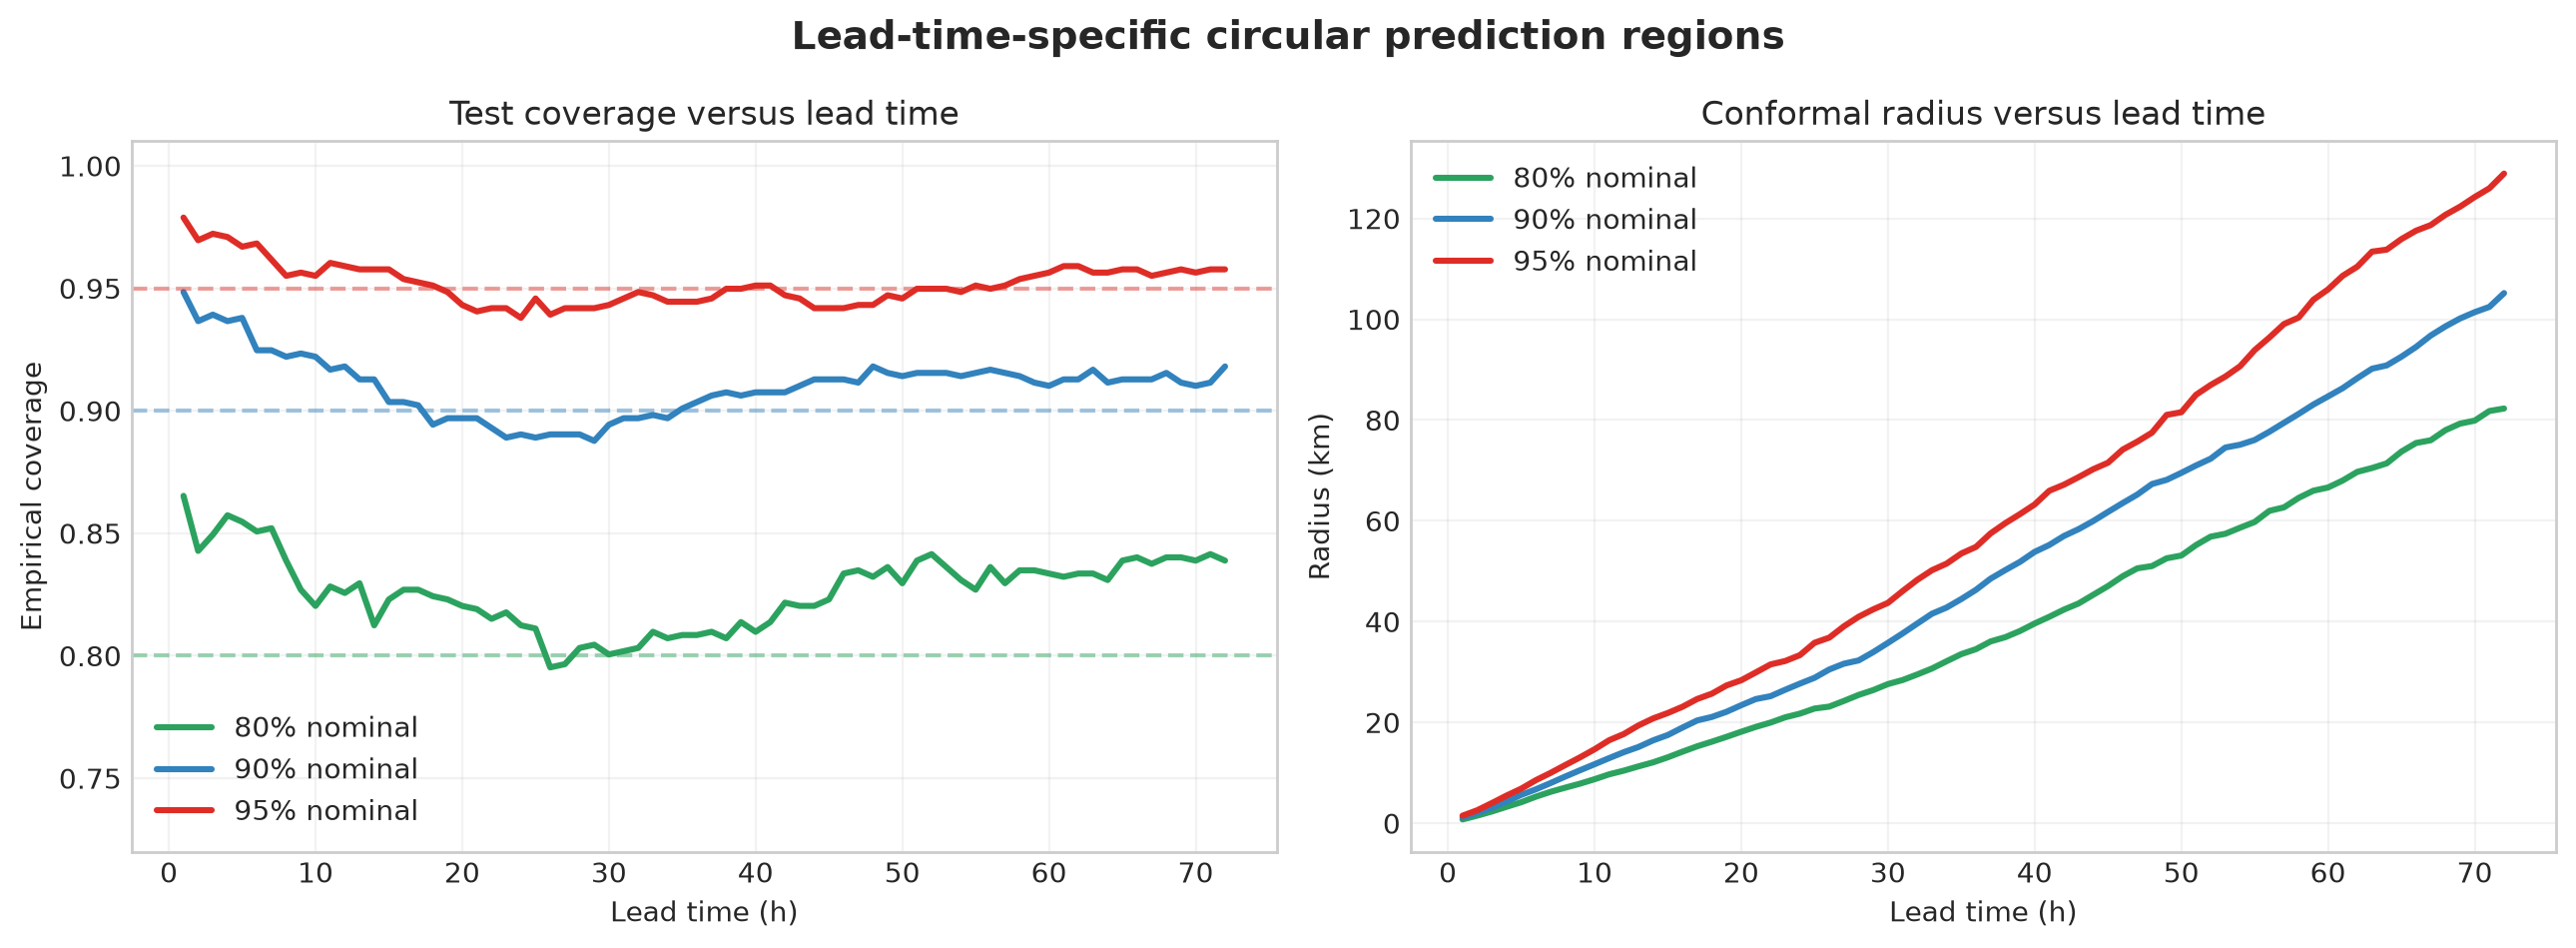

In [7]:
display(Image(filename=str(OUTPUT / "rq3_coverage_and_radius_by_lead.png"), width=1000))

### 读图结论

90% global conformal region 在 24、48、72 h 的半径约为 27.70、67.30、105.20 km，
test coverage 分别约为 89.0%、91.8%、91.8%。半径增长不是 conformal 让模型变差，
而是它忠实反映了 FNN 点预测误差随 lead time 增长。

Coverage 必须和区域大小一起看：把半径无限增大可以获得接近 100% coverage，但没有实际决策价值。

## 6. Global coverage 是否掩盖区域差异？

Global 方法让所有 calibration cases 共用一个 72 h 半径。它总体上达到约 90%，
但不保证每个 ocean regime 内都达到 90%。

,regime,lead_time_hours,n_cases,n_drifters,empirical_coverage,global_radius_km,median_error_km,rmse_km
0,Shelf,24,112,28,0.955,27.696,8.294,12.840
1,Shelf,48,112,28,0.973,67.304,17.419,28.087
2,Shelf,72,112,28,0.964,105.196,25.693,41.614
3,Other Offshore,24,341,41,0.959,27.696,10.030,14.272
4,Other Offshore,48,341,41,0.971,67.304,24.098,32.578
5,Other Offshore,72,341,41,0.965,105.196,40.603,52.602
6,Transition,24,165,43,0.855,27.696,12.172,18.906
7,Transition,48,165,43,0.903,67.304,27.678,42.951
8,Transition,72,165,43,0.897,105.196,41.080,66.189
9,Kuroshio Core,24,139,45,0.712,27.696,20.528,27.167


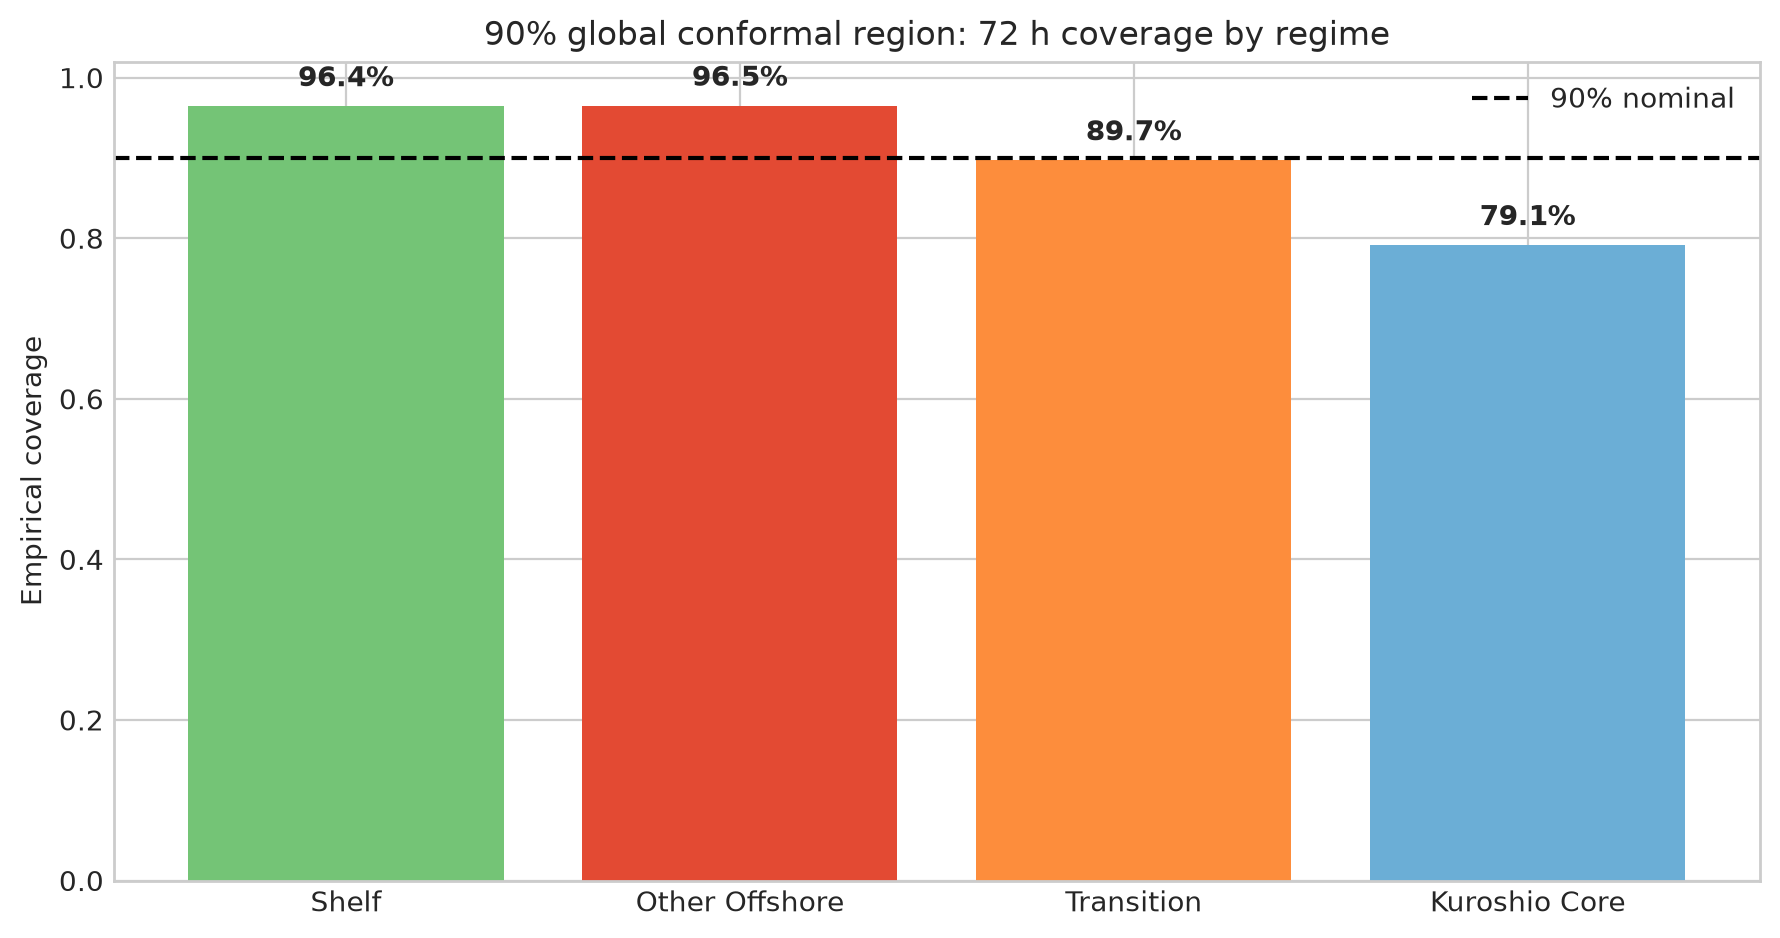

In [8]:
regime_global = pd.read_csv(OUTPUT / "rq3_coverage_by_regime.csv")
display(regime_global.round(3))
display(Image(filename=str(OUTPUT / "rq3_72h_coverage_by_regime.png"), width=850))

关键发现：全体 test cases 的 72 h coverage 为 91.8%，但 Kuroshio Core 只有约 79.1%；
Shelf 和 Other Offshore 则超过 96%。因此“总体有效”不代表“每个海洋环境内都同样可靠”。

## 7. 三种 72 h uncertainty calibration 方法

### 7.1 Global case CP
所有 calibration cases 共用一个半径。优点是样本多、分位数稳定；缺点是不同 regime 可能覆盖不均。

### 7.2 Mondrian case CP
每个 regime 只用该 regime 的 calibration cases 计算自己的半径。它希望改善 **regime-conditional coverage**。
Kuroshio 需要更大的半径，Shelf 则可以使用更小的半径。

### 7.3 Regime drifter-max CP
在每个 regime 内先取每个 calibration drifter 的最大 72 h endpoint error，再做 conformal quantile。
它更接近“一个新 drifter 的全部已观察 cases 是否都被覆盖”，因此通常非常保守、区域更大。
它是 sensitivity analysis，不应被说成无条件的正式保证。

,regime,method,n_cal_cases,n_cal_drifters,n_test_cases,n_test_drifters,radius_km,area_km2,coverage
0,Kuroshio Core,Global case CP,120,42,139,45,105.196,34764.722,0.791
1,Kuroshio Core,Mondrian case CP,120,42,139,45,141.227,62656.641,0.899
2,Kuroshio Core,Regime drifter-max CP,120,42,139,45,195.973,120644.343,0.986
3,Other Offshore,Global case CP,291,32,341,41,105.196,34764.722,0.965
4,Other Offshore,Mondrian case CP,291,32,341,41,93.331,27364.982,0.930
5,Other Offshore,Regime drifter-max CP,291,32,341,41,132.315,54998.435,0.994
6,Shelf,Global case CP,200,31,112,28,105.196,34764.722,0.964
7,Shelf,Mondrian case CP,200,31,112,28,62.869,12417.218,0.911
8,Shelf,Regime drifter-max CP,200,31,112,28,99.425,31055.134,0.946
9,Transition,Global case CP,158,42,165,43,105.196,34764.722,0.897


,method,coverage,mean_area_km2,mean_radius_km,min_regime_coverage,max_regime_coverage
0,Global case CP,0.918,34764.722,105.196,0.791,0.965
1,Mondrian case CP,0.918,35070.902,102.817,0.899,0.930
2,Regime drifter-max CP,0.980,67109.818,143.184,0.946,0.994


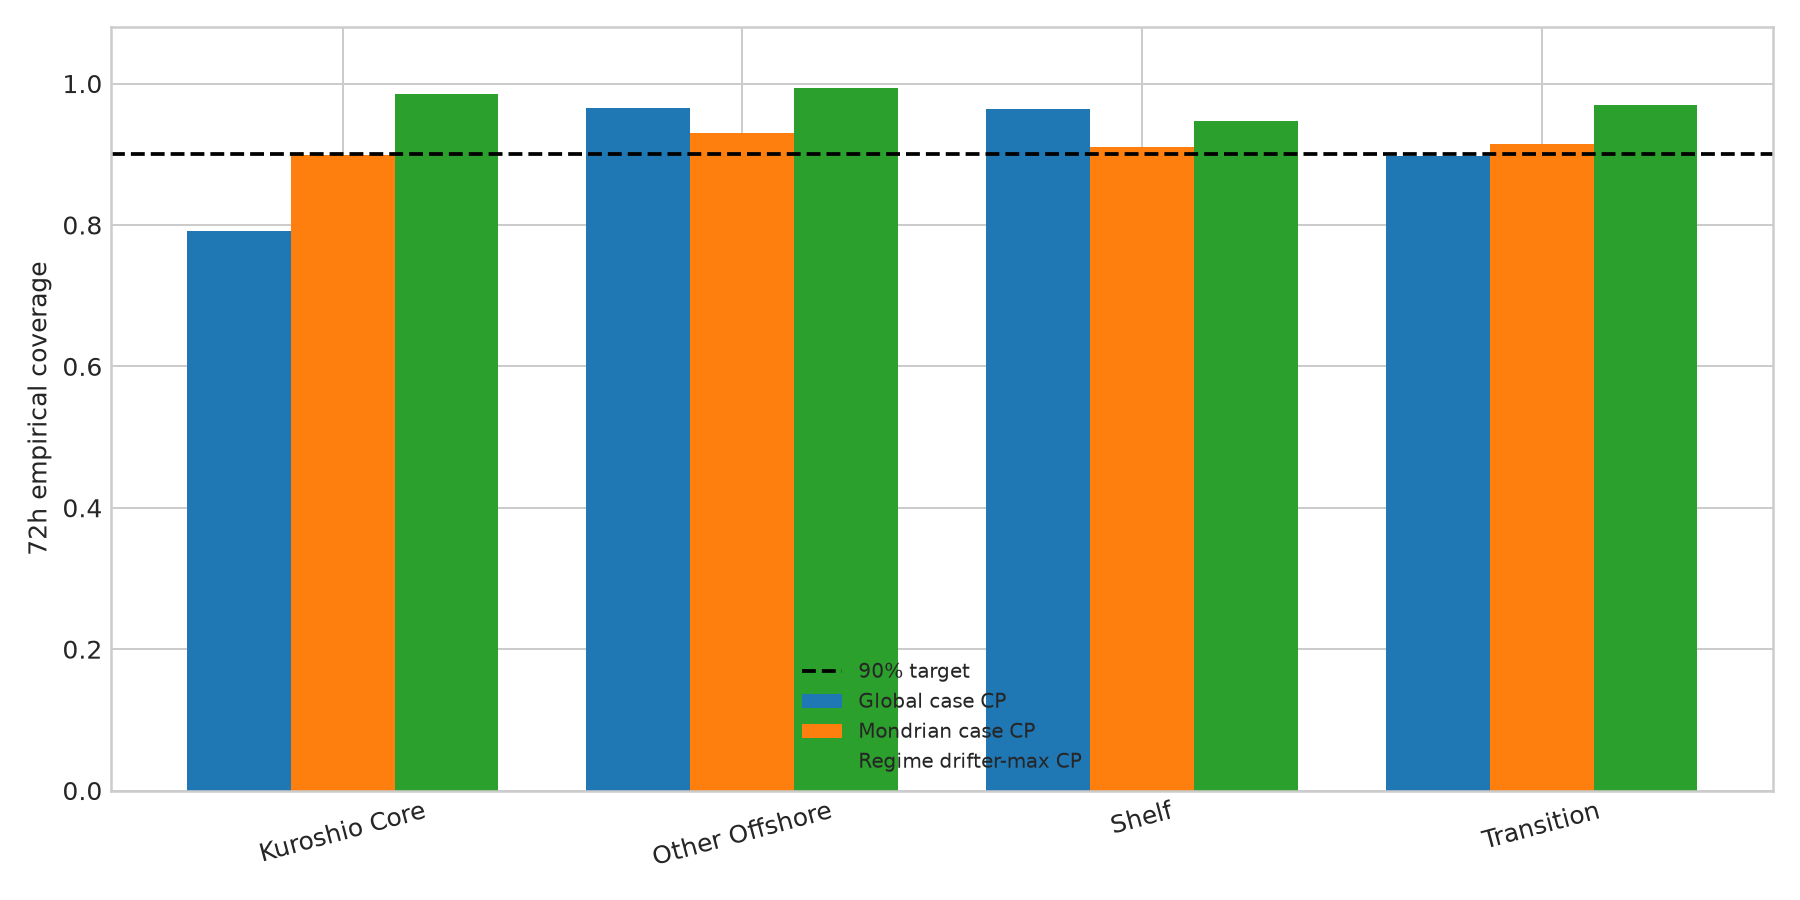

In [9]:
comparison = pd.read_csv(OUTPUT / "rq3_72h_regime_comparison.csv")
overall = pd.read_csv(OUTPUT / "rq3_72h_overall_comparison.csv")
drifter_max = pd.read_csv(OUTPUT / "rq3_drifter_max_coverage.csv")

display(comparison.round(3))
display(overall.round(3))
display(Image(filename=str(OUTPUT / "rq3_regime_coverage_comparison.png"), width=950))

### 如何解释三种方法的取舍？

- Global 和 Mondrian 的总体 coverage 都约为 91.8%；
- Mondrian 将 Kuroshio coverage 从 79.1% 提升到约 89.9%；
- across-regime coverage range 从约 17.4 percentage points 缩小到约 3.1 points；
- 代价是不同区域使用不同半径，case-weighted mean area 约增加 0.88%；
- drifter-max 的总体 case coverage 达到约 98%，但平均面积约翻倍，且“case coverage”不等于
  “一个 drifter 的全部 cases 都被覆盖”。

In [10]:
display(drifter_max.round(3))

,regime,n_test_drifters,all_cases_covered,radius_km
0,Kuroshio Core,45,0.956,195.973
1,Other Offshore,41,0.951,132.315
2,Shelf,28,0.821,99.425
3,Transition,43,0.884,150.880


## 8. Paired test-drifter cluster bootstrap

757 个 test cases 并不独立，因为同一 drifter 可贡献多个 cases。
因此 bootstrap 以完整 test drifter 为重采样单位，并让 Global 与 Mondrian 在相同 bootstrap sample 上配对比较。

这里的区间只表示：在 calibration 半径已经固定的条件下，test drifter 抽样造成多少不确定性。
它不包含 calibration-set sampling uncertainty，也不能修复同一 drifter 内 cases 的相关性问题。

In [11]:
bootstrap = pd.read_csv(OUTPUT / "rq3_paired_cluster_bootstrap_summary.csv")
focus_metrics = [
    "overall_coverage_diff_pp",
    "overall_mean_area_diff_km2",
    "overall_mean_area_diff_pct",
    "regime_coverage_range_diff_pp",
    "Kuroshio Core__coverage_diff_pp",
    "Shelf__coverage_diff_pp",
    "Transition__coverage_diff_pp",
    "Other Offshore__coverage_diff_pp",
]
focus = bootstrap[bootstrap["metric"].isin(focus_metrics)].set_index("metric").loc[focus_metrics]
display(focus[["estimate", "ci95_lower", "ci95_upper", "valid_bootstrap_reps"]].round(3))

,estimate,ci95_lower,ci95_upper,valid_bootstrap_reps
metric,,,,
overall_coverage_diff_pp,0.000,-1.657,1.620,2000
overall_mean_area_diff_km2,306.180,-2299.244,3134.412,2000
overall_mean_area_diff_pct,0.881,-6.614,9.016,2000
regime_coverage_range_diff_pp,-14.310,-19.729,-5.097,2000
Kuroshio Core__coverage_diff_pp,10.791,6.207,16.495,2000
Shelf__coverage_diff_pp,-5.357,-8.667,-1.665,2000
Transition__coverage_diff_pp,1.818,0.000,3.922,2000
Other Offshore__coverage_diff_pp,-3.519,-5.980,-1.719,2000


Bootstrap 支持的主要结论：

- overall coverage difference 的区间跨 0：Mondrian 没有提高总体 coverage；
- Kuroshio coverage 改善约 +10.79 percentage points，95% 区间约 +6.21 到 +16.50；
- regime coverage range 明显缩小，说明不同环境之间的可靠性更均衡；
- 面积差区间跨 0，尚不能说平均区域面积发生了稳定变化。

## 9. Pointwise coverage 与整条轨迹 coverage

逐时 90% 意味着固定某个时刻时约 90% 的位置被覆盖，不代表 72 个时刻会同时全部被覆盖。

整轨迹 band 使用 calibration case 的最大标准化误差：

$$S_i=\max_{t=1,\ldots,72}\frac{e_{i,t}}{m_t},$$

然后对 $S_i$ 做 conformal calibration。它会产生更宽的 band，但目标是覆盖整条轨迹。

In [12]:
trajectory = pd.read_csv(OUTPUT / "rq3_simultaneous_trajectory_summary.csv")
display(trajectory.round(3))

,method,whole_trajectory_coverage,radius_24h_km,radius_48h_km,radius_72h_km
0,Pointwise 90% radii; all 72 positions required,0.741,27.696,67.304,105.196
1,Calibrated 90% simultaneous trajectory band,0.934,47.476,103.782,166.751


结果表明：把 72 个逐时 90% 圆串起来后，只有约 74.1% 的 test trajectories 在所有时刻都被覆盖；
专门校准的 simultaneous band 则达到约 93.4%，但 72 h 半径扩大到约 166.75 km。

因此必须先明确实际问题：

- 只关心某个特定时刻的位置范围：使用 pointwise region；
- 希望整个 72 h 过程中都尽量不漏掉目标：使用 simultaneous trajectory band。

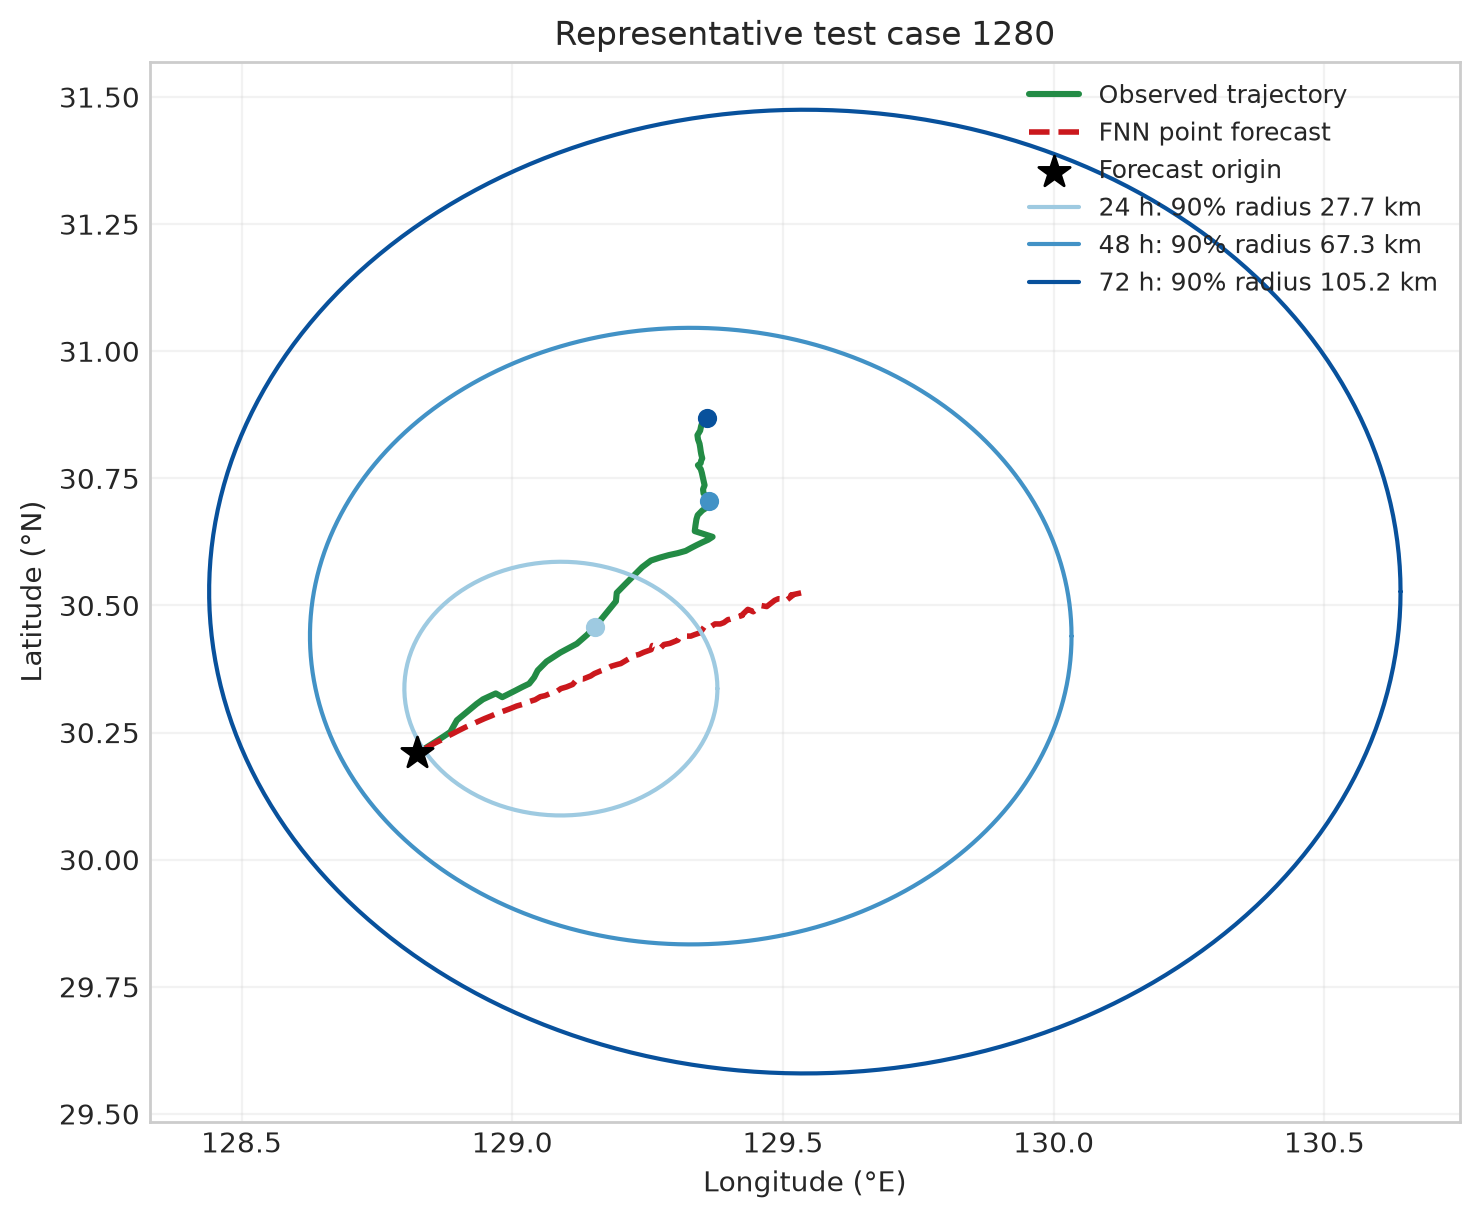

In [13]:
display(Image(filename=str(OUTPUT / "rq3_representative_case_regions.png"), width=750))

## 10. 独立 integrity audit：代码算对了吗？

Audit 检查的不是“conformal assumptions 一定成立”，而是：

- case IDs 是否唯一且与 RQ1 对齐；
- training/calibration/test 是否存在 drifter leakage；
- 5,117 × 72 error matrix 是否完整、有限、非负；
- calibration/test case 数是否分别为 769/757；
- 半径、case coverage、drifter coverage 是否能够独立重算；
- RQ1 与 RQ3 的每个 test case 72 h error 是否一致。

In [14]:
audit = pd.read_csv(OUTPUT / "rq3_integrity_audit_checks.csv")
display(audit)
print(f"Audit 通过：{int(audit['passed'].sum())}/{len(audit)}")
assert audit["passed"].all(), "完整性审计未全部通过，请检查 FAIL 项。"

,check,passed,detail
0,Unique case IDs,True,NaN
1,Origin/meta order and case IDs match,True,NaN
2,Expected data dimensions,True,"5117 cases; errors (5117, 72)"
3,Finite prediction errors,True,NaN
4,Nonnegative prediction errors,True,NaN
5,Calibration case count,True,769
6,Test case count,True,757
7,Calibration/test case rows disjoint,True,NaN
8,Calibration/test drifters disjoint,True,66 cal; 71 test
9,Training/calibration/test drifters disjoint,True,NaN


Audit 通过：42/42


In [15]:
audit_quantiles = pd.read_csv(OUTPUT / "rq3_audit_calibration_quantiles.csv")
audit_case = pd.read_csv(OUTPUT / "rq3_audit_case_level_coverage.csv")
audit_drifter = pd.read_csv(OUTPUT / "rq3_audit_drifter_level_coverage.csv")

display(audit_quantiles.round(3))
display(audit_drifter[[
    "regime", "method", "n_test_drifters", "all_cases_covered_drifters",
    "drifter_level_all_case_coverage",
]].round(3))

,regime,n_cal_cases,n_cal_drifters,n_test_cases,n_test_drifters,global_radius_km,mondrian_radius_km,drifter_max_radius_km
0,Kuroshio Core,120,42,139,45,105.196,141.227,195.973
1,Other Offshore,291,32,341,41,105.196,93.331,132.315
2,Shelf,200,31,112,28,105.196,62.869,99.425
3,Transition,158,42,165,43,105.196,117.177,150.880


,regime,method,n_test_drifters,all_cases_covered_drifters,drifter_level_all_case_coverage
0,Kuroshio Core,Global case CP,45,22,0.489
1,Kuroshio Core,Mondrian case CP,45,32,0.711
2,Kuroshio Core,Regime drifter-max CP,45,43,0.956
3,Other Offshore,Global case CP,41,30,0.732
4,Other Offshore,Mondrian case CP,41,24,0.585
5,Other Offshore,Regime drifter-max CP,41,39,0.951
6,Shelf,Global case CP,28,24,0.857
7,Shelf,Mondrian case CP,28,20,0.714
8,Shelf,Regime drifter-max CP,28,23,0.821
9,Transition,Global case CP,43,29,0.674


## 11. 统计假设与必须主动说明的限制

1. **同一 drifter 内 cases 相关。** Case-level split conformal 的标准 finite-sample validity
   依赖 exchangeability；在这些 observational data 中不能自动认为完全成立。
2. **Drifter-max 也需要额外假设。** 需要 whole-drifter exchangeability 和相近的每个 drifter case sampling；
   本项目并未证明这些条件。
3. **Test-informed method development。** Mondrian 方法是在看见 global method 的 regime undercoverage 后发展出来的，
   因此 Global–Mondrian 比较应称为 exploratory，而不是完全 untouched confirmatory test。
4. **Bootstrap 条件于固定 calibration radii。** 它没有传播 calibration-set sampling uncertainty。
5. **圆形区域忽略方向。** 沿流向与横流向误差可能不同；后续可考虑 conformal ellipse。
6. **泛化范围有限。** 结论适用于与本项目 calibration/test 相似的 Region A GDP drifter cases，
   不能直接外推到全球海洋、未来极端气候或所有漂浮物体。

最重要的措辞边界：**42/42 audit passed 只说明数据对齐和数值计算一致，不等于理论假设已经得到证明。**

## 12. RQ3 最终结论

- Global split conformal 把固定 FNN 点预测转换成了总体上接近 nominal coverage 的圆形预测区域；
- 90% global region 在 72 h 的半径约为 105.20 km，总体 test coverage 约为 91.8%；
- 但 Kuroshio Core 的 coverage 只有约 79.1%，说明总体 reliability 掩盖了明显的环境异质性；
- Mondrian calibration 将 Kuroshio coverage 提升到约 89.9%，并显著缩小不同 regime 之间的 coverage gap；
- 这种改善并不来自更准确的 FNN，而是来自更符合各区域误差尺度的 uncertainty calibration；
- 若要求整条 72 h 轨迹同时覆盖，必须使用专门的 simultaneous band，并接受更大的预测区域。

## 13. 可直接用于最终报告的英文表述

**Methods**

We applied split conformal prediction to the fixed FNN trajectory forecasts. The FNN was fitted using
training drifters only. Lead-time-specific Haversine errors from 769 held-out calibration cases were used as
nonconformity scores, and finite-sample-corrected quantiles defined circular prediction regions centred on
the FNN forecasts. Coverage and region size were evaluated on 757 held-out test cases. We additionally
compared global calibration with regime-specific Mondrian calibration and a conservative drifter-maximum
sensitivity analysis. Uncertainty in method comparisons was assessed using 2,000 paired bootstrap samples
of complete test drifters.

**Results**

The global 90% conformal region achieved 91.8% coverage at 72 h, with a radius of 105.20 km. However,
coverage varied substantially across ocean regimes, reaching only 79.1% in the Kuroshio Core while
exceeding 96% in the Shelf and Other Offshore regimes. Regime-specific Mondrian calibration increased
Kuroshio coverage to 89.9% and reduced the across-regime coverage range without materially changing overall
coverage. A separately calibrated simultaneous band covered 93.4% of complete 72 h trajectories, but
required substantially larger regions.

**Interpretation**

Conformal calibration provided useful marginal uncertainty quantification, but a single global radius did
not deliver equally reliable forecasts across heterogeneous ocean environments. Regime-aware calibration
improved coverage balance, although the comparison remains exploratory because the extension was motivated
by observed regime-specific undercoverage.

## 14. 输出文件索引

In [16]:
output_index = pd.DataFrame([
    {
        "file": p.name,
        "type": p.suffix.lstrip(".").upper(),
        "size_kB": round(p.stat().st_size / 1024, 1),
    }
    for p in sorted(OUTPUT.iterdir()) if p.is_file()
])
display(output_index)
print(f"共 {len(output_index)} 个正式输出文件。")

,file,type,size_kB
0,rq3_72h_coverage_by_regime.png,PNG,60.0
1,rq3_72h_overall_comparison.csv,CSV,0.4
2,rq3_72h_regime_comparison.csv,CSV,1.3
3,rq3_audit_calibration_quantiles.csv,CSV,0.4
4,rq3_audit_case_level_coverage.csv,CSV,0.9
5,rq3_audit_drifter_level_coverage.csv,CSV,2.5
6,rq3_case_id_error_audit.csv,CSV,38.8
7,rq3_cluster_bootstrap_coverage.csv,CSV,0.3
8,rq3_conformal_quantiles.csv,CSV,6.3
9,rq3_coverage_and_radius_by_lead.png,PNG,192.3


共 19 个正式输出文件。
